# Test LULC outputs against the held-out test data

Compares LULC classifications with the frozen test points (`TEST_TILES` in `ldn/training_data.py`, written by the
`test-data-generate-*` Makefile targets to `dep_ls_lulc/test_data/{TEST_DATA_VERSION}/`). This is seperate to the 
validation workflow in the README: programmatic validation used to compare data and model versions. That uses data created 
by locals/experts. These test labels come from 2-of-3 agreement between ESA WorldCover, ESA CCI and Impact Observatory, 
so they are a reference, not ground truth.

1. Load the test points for every test tile.
2. Find each tile's LULC classification and sample it at the test points (points are 30 m pixel centres on the same
   grid, so this is an exact pixel lookup).
3. Score: confusion matrix, overall accuracy, Cohen's kappa, per-class precision (user's accuracy), recall (producer's
   accuracy) and F1, with 95% confidence intervals from a bootstrap that resamples whole tiles.
4. Optionally compare two LULC versions on the same points (exact McNemar test).
5. Write a markdown report and confusion matrix figure.

We should expect LULC v0-0-9 to perform badly in the non-Pacific region because it uses only Pacific training data.

In [1]:
# Reload functions during development
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
from urllib.error import HTTPError

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from dep_tools.namers import GenericItemPath
from rustac import search_sync
from scipy.stats import binomtest
from sklearn.metrics import cohen_kappa_score, confusion_matrix, precision_recall_fscore_support

from ldn.training_data import TEST_TILES
from ldn.typology import classes_flipped
from ldn.utils import (
    CLASS_ATTR,
    LULC_DATASET_ID,
    SENSOR,
    TEST_DATA_VERSION,
    TRAINING_DATA_YEAR,
    WGS84,
    dataset_prefix,
    owner_for_region,
    parse_tile_id,
)

In [3]:
BUCKET_URL = "https://dep-public-staging.s3.us-west-2.amazonaws.com"
TEST_DATA_OWNER = "dep"  # The test-data Makefile targets write both regions under dep_ls_lulc
LABEL_YEAR = TRAINING_DATA_YEAR  # Test labels are for 2020, the year the source LULC products overlap
LULC_YEAR = "2025"  # TODO: Set to LABEL_YEAR once 2020 LULC exists. Only 2000 and 2025 are classified so far.
LULC_VERSIONS = ["0-0-9"]  # LULC versions in S3. Add a second (e.g. ["0-0-9", "0-1-1"]) to compare two
NODATA = 255
N_BOOTSTRAP = 1000
SEED = 0
REPORT_DIR = Path("reports_test")  # Relative to this notebook (notebooks/LULC_Testing)

CLASSES = sorted(c for c in classes_flipped if c != NODATA)
LABELS = [classes_flipped[c] for c in CLASSES]

## Load test points

In [4]:
def load_test_points(tiles: list, version: str, year: str) -> tuple[gpd.GeoDataFrame, list[str]]:
    """Load the test points for each tile from S3.

    Args:
        tiles: (tile_id, region, country) tuples, e.g. TEST_TILES.
        version: Test data version, e.g. TEST_DATA_VERSION.
        year: Year of the test labels.

    Returns:
        Points with reference class, tile_id and region (EPSG:4326), and the tile ids that have no test data yet.
    """
    prefix = dataset_prefix(TEST_DATA_OWNER, SENSOR, LULC_DATASET_ID)
    frames, missing = [], []
    for tile_id, region, _ in tiles:
        x, y = parse_tile_id(tile_id)
        url = f"{BUCKET_URL}/{prefix}/test_data/{version}/{region}/{x:03d}/{y:03d}/{year}/samples.csv"
        try:
            df = pd.read_csv(url, usecols=[CLASS_ATTR, "geometry"])
        except HTTPError:
            missing.append(tile_id)
            continue
        frames.append(df.assign(tile_id=tile_id, region=region))
    points = pd.concat(frames, ignore_index=True).rename(columns={CLASS_ATTR: "reference"})
    return gpd.GeoDataFrame(points, geometry=gpd.GeoSeries.from_wkt(points["geometry"]), crs=WGS84), missing


points, missing_test_data = load_test_points(TEST_TILES, TEST_DATA_VERSION, LABEL_YEAR)
print(f"Loaded {len(points)} test points from {points['tile_id'].nunique()} of {len(TEST_TILES)} test tiles")
print(f"No test data yet for: {missing_test_data}")
points.groupby(["region", "reference"]).size().unstack(fill_value=0).rename(columns=classes_flipped)

Loaded 67554 test points from 27 of 27 test tiles
No test data yet for: []


reference,Tree cover,Grassland,Cropland,Wetland,Built-up,Water,Other
region,,,,,,,
non-pacific,14830,5561,1888,2163,2685,6161,1798
pacific,13684,3528,396,699,861,12498,802


## Sample LULC at the test points

In [5]:
def lulc_hrefs(tiles: list, version: str, year: str) -> dict[str, str]:
    """Find the LULC classification COG for each tile from the STAC-Geoparquet index of each owner.

    Args:
        tiles: (tile_id, region, country) tuples.
        version: LULC version, e.g. "0-0-9".
        year: LULC year.

    Returns:
        Classification COG URL keyed by tile id, for tiles that have a LULC output.
    """
    hrefs = {}
    for owner in sorted({owner_for_region(region) for _, region, _ in tiles}):
        prefix = dataset_prefix(owner, SENSOR, LULC_DATASET_ID)
        # Same ID construction as the LULC writer (itempath.basename)
        namer = GenericItemPath(sensor=SENSOR, dataset_id=LULC_DATASET_ID, version=version, time=year, prefix=owner)
        ids = {namer.basename(parse_tile_id(t)): t for t, region, _ in tiles if owner_for_region(region) == owner}
        for item in search_sync(f"{BUCKET_URL}/{prefix}/{version}/{prefix}.parquet", ids=list(ids)):
            hrefs[ids[item["id"]]] = item["assets"]["classification"]["href"]
    return hrefs


def sample_lulc(points: gpd.GeoDataFrame, hrefs: dict[str, str]) -> pd.Series:
    """Sample the LULC classification at each point.

    Args:
        points: Test points with a tile_id column.
        hrefs: Classification COG URL keyed by tile id.

    Returns:
        Predicted class per point. NaN where the tile has no LULC output, NODATA where the model was not confident.
    """
    predicted = pd.Series(np.nan, index=points.index)
    for tile_id, tile_points in points.groupby("tile_id"):
        if tile_id not in hrefs:
            continue
        with rasterio.open(hrefs[tile_id]) as src:
            xy = tile_points.to_crs(src.crs).geometry
            predicted[tile_points.index] = [value[0] for value in src.sample(zip(xy.x, xy.y))]
    return predicted


for version in LULC_VERSIONS:
    hrefs = lulc_hrefs(TEST_TILES, version, LULC_YEAR)
    points[f"predicted_{version}"] = sample_lulc(points, hrefs)
    print(f"LULC {version} ({LULC_YEAR}): found for {len(hrefs)} of {len(TEST_TILES)} test tiles")

if LULC_YEAR != LABEL_YEAR:
    print(f"Warning: comparing {LABEL_YEAR} labels with {LULC_YEAR} LULC. Real change counts as error.")

LULC 0-0-9 (2025): found for 27 of 27 test tiles


## Coverage

In [6]:
version = LULC_VERSIONS[0]
predicted_col = f"predicted_{version}"
version_dir = REPORT_DIR / version
version_dir.mkdir(parents=True, exist_ok=True)
coverage = {
    "test points": len(points),
    "tile has no LULC": int(points[predicted_col].isna().sum()),
    "LULC nodata (below probability threshold or no geomad)": int((points[predicted_col] == NODATA).sum()),
}
scored = points[points[predicted_col].notna() & (points[predicted_col] != NODATA)].copy()
scored["predicted"] = scored[predicted_col].astype(int)
coverage["scored points"] = len(scored)
assert not scored.empty, f"No test points have LULC {version} for {LULC_YEAR}. Run LULC for the test tiles first."
pd.Series(coverage, name="points")

test points                                               67554
tile has no LULC                                              0
LULC nodata (below probability threshold or no geomad)      974
scored points                                             66580
Name: points, dtype: int64

## Accuracy with tile bootstrap confidence intervals

In [7]:
def accuracy_metrics(reference: np.ndarray, predicted: np.ndarray) -> dict[str, float]:
    """Overall accuracy, Cohen's kappa, macro F1, and per-class precision, recall and F1.

    Args:
        reference: Reference classes.
        predicted: Predicted classes.

    Returns:
        Metric name to value. Per-class metrics are NaN when the class is absent.
    """
    precision, recall, f1, _ = precision_recall_fscore_support(
        reference, predicted, labels=CLASSES, zero_division=np.nan
    )
    metrics = {
        "overall_accuracy": float(np.mean(reference == predicted)),
        "kappa": cohen_kappa_score(reference, predicted, labels=CLASSES),
        "macro_f1": float(np.nanmean(f1)),
    }
    for c, p, r, f in zip(CLASSES, precision, recall, f1):
        metrics |= {f"precision_{c}": p, f"recall_{c}": r, f"f1_{c}": f}
    return metrics


def tile_bootstrap(scored: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    """95% confidence intervals for each metric by resampling whole tiles with replacement.

    Points within a tile are spatially correlated, so resampling tiles rather than points gives honest intervals.

    Args:
        scored: Points with reference, predicted and tile_id columns.
        n: Number of bootstrap replicates.
        seed: Random seed.

    Returns:
        ci_low and ci_high for each metric.
    """
    rng = np.random.default_rng(seed)
    tiles = [tile for _, tile in scored.groupby("tile_id")]
    replicates = []
    for _ in range(n):
        sample = pd.concat([tiles[i] for i in rng.integers(len(tiles), size=len(tiles))])
        replicates.append(accuracy_metrics(sample["reference"].to_numpy(), sample["predicted"].to_numpy()))
    return pd.DataFrame(replicates).quantile([0.025, 0.975]).T.set_axis(["ci_low", "ci_high"], axis=1)


metrics = pd.Series(accuracy_metrics(scored["reference"].to_numpy(), scored["predicted"].to_numpy()), name="value")
metrics = pd.concat([metrics, tile_bootstrap(scored, N_BOOTSTRAP, SEED)], axis=1)

summary = metrics.loc[["overall_accuracy", "kappa", "macro_f1"]]
per_class = pd.DataFrame(
    {
        "class": LABELS,
        "reference points": [int((scored["reference"] == c).sum()) for c in CLASSES],
        "predicted points": [int((scored["predicted"] == c).sum()) for c in CLASSES],
        **{
            f"{name} (95% CI)": [
                f"{metrics.loc[f'{key}_{c}', 'value']:.2f} ({metrics.loc[f'{key}_{c}', 'ci_low']:.2f}-"
                f"{metrics.loc[f'{key}_{c}', 'ci_high']:.2f})"
                for c in CLASSES
            ]
            for key, name in [("precision", "user's accuracy"), ("recall", "producer's accuracy"), ("f1", "F1")]
        },
    }
)
display(summary.round(3))
per_class

,value,ci_low,ci_high
overall_accuracy,0.810,0.731,0.870
kappa,0.739,0.642,0.809
macro_f1,0.628,0.562,0.680


,class,reference points,predicted points,user's accuracy (95% CI),producer's accuracy (95% CI),F1 (95% CI)
0,Tree cover,28496,26813,0.93 (0.91-0.95),0.87 (0.74-0.95),0.90 (0.82-0.94)
1,Grassland,9056,8939,0.64 (0.46-0.77),0.63 (0.53-0.70),0.63 (0.51-0.72)
2,Cropland,2229,3783,0.20 (0.08-0.41),0.34 (0.21-0.48),0.25 (0.11-0.42)
3,Wetland,2787,2221,0.77 (0.59-0.87),0.62 (0.45-0.74),0.68 (0.54-0.78)
4,Built-up,3535,5752,0.50 (0.37-0.62),0.81 (0.73-0.88),0.61 (0.50-0.71)
5,Water,17890,18053,0.96 (0.93-0.98),0.97 (0.95-0.98),0.97 (0.94-0.98)
6,Other,2587,1019,0.60 (0.48-0.89),0.24 (0.08-0.46),0.34 (0.15-0.51)


## Confusion matrix

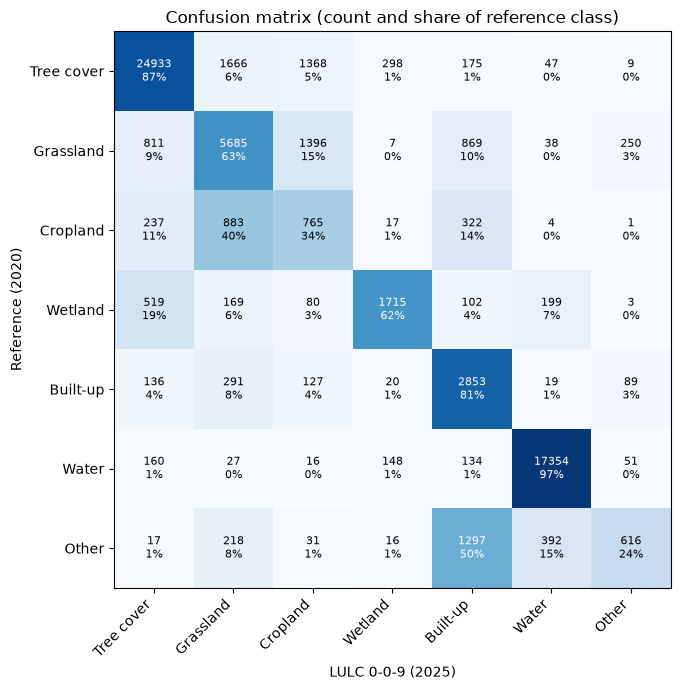

In [8]:
counts = confusion_matrix(scored["reference"], scored["predicted"], labels=CLASSES)
row_share = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(row_share, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        colour = "white" if row_share[i, j] > 0.5 else "black"
        ax.text(j, i, f"{counts[i, j]}\n{row_share[i, j]:.0%}", ha="center", va="center", fontsize=8, color=colour)
ax.set_xticks(range(len(CLASSES)), LABELS, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), LABELS)
ax.set_xlabel(f"LULC {version} ({LULC_YEAR})")
ax.set_ylabel(f"Reference ({LABEL_YEAR})")
ax.set_title("Confusion matrix (count and share of reference class)")
fig.tight_layout()
confusion_png = version_dir / f"confusion_matrix_{LULC_YEAR}.png"
fig.savefig(confusion_png, dpi=150)

## Accuracy by region and tile

In [9]:
def group_accuracy(scored: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    """Point count and overall accuracy per group.

    Args:
        scored: Points with reference and predicted columns.
        by: Columns to group by.

    Returns:
        points and overall_accuracy per group.
    """
    correct = scored["reference"] == scored["predicted"]
    return correct.groupby([scored[c] for c in by]).agg(points="size", overall_accuracy="mean").round(3)


by_region = group_accuracy(scored, ["region"])
by_tile = group_accuracy(scored, ["region", "tile_id"]).sort_values("overall_accuracy")
display(by_region)
by_tile

,points,overall_accuracy
region,,
non-pacific,34521,0.744
pacific,32059,0.881


points  overall_accuracy
region      tile_id                          
non-pacific 193_120    3256             0.256
pacific     094_035    1745             0.533
non-pacific 128_132    3169             0.621
            131_135    2606             0.706
            335_092    3507             0.714
            312_106    3040             0.731
            183_123    2891             0.742
            133_128    3412             0.780
            138_129    3114             0.790
pacific     050_041    2145             0.791
            026_059    2711             0.840
            073_019    2703             0.847
            051_017    2907             0.867
non-pacific 264_097    2749             0.893
pacific     089_016    2527             0.897
            040_049    2683             0.909
            050_029    2242             0.923
            033_031    2202             0.930
            032_028    2099             0.937
            064_032    2161             0.949
            051_052    2139             0.954
non-pacific 149_107    2692             0.958
pacific     067_016    1765             0.961
            115_014    1966             0.966
non-pacific 281_109    1856             0.969
            151_106    2229             0.991
pacific     104_022      64             1.000

## Compare two LULC versions (exact McNemar test)

In [10]:
def mcnemar_exact(reference: np.ndarray, predicted_a: np.ndarray, predicted_b: np.ndarray) -> dict[str, float]:
    """Exact McNemar test of whether two classifications have different error rates on the same points.

    Only points where exactly one version is correct count. Points within a tile are correlated, so treat the
    p-value as indicative rather than exact.

    Args:
        reference: Reference classes.
        predicted_a: Classes from version A.
        predicted_b: Classes from version B.

    Returns:
        Points only A got right, points only B got right, and the two-sided p-value.
    """
    a_only = int(np.sum((predicted_a == reference) & (predicted_b != reference)))
    b_only = int(np.sum((predicted_b == reference) & (predicted_a != reference)))
    p_value = binomtest(a_only, a_only + b_only, 0.5).pvalue if a_only + b_only else 1.0
    return {"only_a_correct": a_only, "only_b_correct": b_only, "p_value": p_value}


comparison = None
if len(LULC_VERSIONS) == 2:
    cols = [f"predicted_{v}" for v in LULC_VERSIONS]
    both = points[points[cols].notna().all(axis=1) & (points[cols] != NODATA).all(axis=1)]
    comparison = mcnemar_exact(both["reference"].to_numpy(), *(both[c].to_numpy() for c in cols))
    comparison |= {f"accuracy_{v}": float(np.mean(both[c] == both["reference"])) for v, c in zip(LULC_VERSIONS, cols)}
    comparison["points"] = len(both)
comparison

## Write the report

In [11]:
def markdown_table(df: pd.DataFrame) -> str:
    """Render a DataFrame as a markdown table.

    Args:
        df: Table to render. The index is written as columns.

    Returns:
        Markdown table string.
    """
    df = df.reset_index().rename(columns={"index": ""})
    rows = [list(map(str, df.columns)), ["-"] * len(df.columns), *df.astype(str).values.tolist()]
    return "\n".join(f"| {' | '.join(row)} |" for row in rows)


year_note = (
    f"\n**Warning:** labels are for {LABEL_YEAR} but the LULC is for {LULC_YEAR}, so real land cover change counts as "
    "error.\n"
    if LULC_YEAR != LABEL_YEAR
    else ""
)
comparison_section = (
    f"""
## Version comparison (exact McNemar test)

{markdown_table(pd.Series(comparison, name="value").to_frame())}

A small p-value means the two versions have different accuracy on the same points.
"""
    if comparison
    else ""
)
summary_table = summary.rename(
    index={"overall_accuracy": "Overall accuracy", "kappa": "Cohen's kappa", "macro_f1": "Macro F1"}
)

n_tiles = points["tile_id"].nunique()
report = f"""# LULC test report: version {version}, {LULC_YEAR}

- Test data: version {TEST_DATA_VERSION}, labels for {LABEL_YEAR}, {n_tiles} of {len(TEST_TILES)} test tiles
- LULC: version {version}, year {LULC_YEAR}
- Tiles with no test data yet: {", ".join(missing_test_data) or "none"}
{year_note}
## Coverage

{markdown_table(pd.Series(coverage, name="points").to_frame())}

## Overall accuracy

95% confidence intervals from {N_BOOTSTRAP} bootstrap replicates that resample whole tiles.

{markdown_table(summary_table.round(3))}

## Per class

User's accuracy is precision (of points mapped as a class, the share that are that class). Producer's accuracy is
recall (of points that are a class, the share mapped as it).

{markdown_table(per_class.set_index("class"))}

## Confusion matrix

![Confusion matrix]({confusion_png.name})

## By region

{markdown_table(by_region)}

## By tile (lowest accuracy first)

{markdown_table(by_tile)}
{comparison_section}
## Caveats

- Reference labels come from 2-of-3 agreement between ESA WorldCover, ESA CCI and Impact Observatory, not ground truth.
  Agreement favours easy, homogeneous areas, so these accuracies are likely higher than on the whole map.
- Points are sampled with a minimum per class, so overall accuracy is a sample statistic, not an area-weighted map
  accuracy.
- Points within a tile are spatially correlated. The confidence intervals resample tiles to account for this, but with
  few tiles they are wide and approximate.
"""
report_path = version_dir / f"test_lulc_{LULC_YEAR}.md"
report_path.write_text(report)
print(f"Wrote {report_path}")

Wrote reports_test/0-0-9/test_lulc_2025.md
